# 焚化爐圖解：ML 慢慢學 EP02 的程式

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ntanh-ml/ml-manmanxue/blob/main/v03-incinerator-data/notebook.ipynb)

這本 notebook 產生影片裡**每一張資料圖**。所有資料都是**模擬資料，非實廠數據**，不代表任何一座真實焚化廠。
This notebook generates every data chart in EP02 of the YouTube channel ML 慢慢學 (https://www.youtube.com/@ml-step-by-step). All data are **simulated** and do not describe any real plant.

| 段落 | 對應影片 |
|---|---|
| 1. 模擬垃圾熱值 | 第 4 段 |
| 2. 進料不變時：熱值一變，爐溫和蒸汽量跟著變 | 第 4 段 |
| 3. 熱負荷上限（簡化示意） | 第 4 段 |
| 4. 焚化廠的資料：一條條時間序列 | 第 5 段 |
| 5. 三種資料：即時、慢半拍、很少量到 | 第 6 段 |
| 6. 軟感測器：用量得到的，推估熱值 | 第 6、8 段 |
| 7. 提早示警 | 第 8 段 |
| 8. 匯出資料給影片使用 | — |

參考：Tang, J., Wang, T., Xia, H., & Cui, C. (2024). An overview of artificial intelligence application for optimal control of municipal solid waste incineration process. *Sustainability*, 16(5), 2042；Madsen, O. H. (2009). NAWTEC17；《廢棄物焚化爐戴奧辛管制及排放標準》。

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager

PAPER, INK, RED, BLUE, AMBER = "#F6F1E7", "#3B2F2A", "#D8573C", "#4FA3D1", "#D79A2B"
LABEL = "模擬資料，非實廠數據"

# Chinese font for the plots. Uses LXGW WenKai TC (OFL) if present; otherwise Noto Sans CJK.
# On Google Colab the Noto CJK font is installed automatically so the Chinese labels display correctly.
import subprocess, sys
FONT = Path("../../tools/fonts/LXGWWenKaiTC-Medium.ttf")
CJK = Path("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc")
if not FONT.exists() and not CJK.exists() and "google.colab" in sys.modules:
    print("正在安裝中文字型（約 30 秒）…")
    if subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-cjk"]).returncode != 0:
        subprocess.run(["apt-get", "-qq", "update"])
        subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-cjk"])
for f in (FONT, CJK):
    if f.exists():
        font_manager.fontManager.addfont(str(f))
        plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(f)).get_name()
        break
plt.rcParams.update({"figure.facecolor": PAPER, "axes.facecolor": PAPER, "axes.edgecolor": INK,
                     "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "text.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

def tag(ax):
    ax.text(0.99, 0.97, LABEL, transform=ax.transAxes, ha="right", va="top", fontsize=8, color=RED)

def lag(x, tau):
    # 一階延遲：輸出慢慢追上輸入，tau 越大越慢 (first-order lag)
    y = np.empty_like(x); y[0] = x[0]
    for i in range(1, len(x)):
        y[i] = y[i - 1] + (x[i] - y[i - 1]) / tau
    return y

## 1. 模擬垃圾熱值
每分鐘一筆，共 600 分鐘（10 小時）。熱值用 AR(1) 隨機過程模擬：今天這一斗和上一斗有關，但會慢慢漂移。
平均值與範圍參考公開報導（台中焚化爐 2021 年平均約 2300 大卡/公斤，設計值 1500；評論文章稱 2300–2500），這裡取平均 2050、範圍 1500–2500 之內，只為示意。

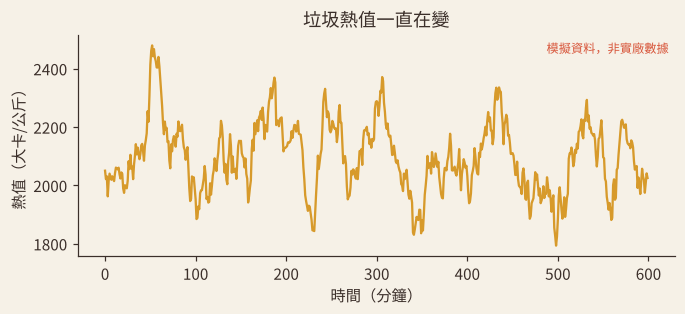

熱值：平均 2097，最低 1793，最高 2479 大卡/公斤（模擬）


In [2]:
rng = np.random.default_rng(2026)
N = 600                                   # minutes, simulated
MU, SD, PHI = 2050.0, 150.0, 0.97          # kcal/kg
lhv = np.empty(N); lhv[0] = MU
for i in range(1, N):
    lhv[i] = MU + PHI * (lhv[i - 1] - MU) + rng.normal(0, SD * np.sqrt(1 - PHI ** 2))
lhv = np.clip(lhv, 1500, 2500)
assert 1500 <= lhv.min() and lhv.max() <= 2500

t = np.arange(N)
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.plot(t, lhv, color=AMBER)
ax.set_xlabel("時間（分鐘）"); ax.set_ylabel("熱值（大卡/公斤）"); ax.set_title("垃圾熱值一直在變")
tag(ax); plt.show()
print(f"熱值：平均 {lhv.mean():.0f}，最低 {lhv.min():.0f}，最高 {lhv.max():.0f} 大卡/公斤（模擬）")

## 2. 進料不變時：熱值一變，爐溫和蒸汽量跟著變
假設每分鐘送進一樣多的垃圾，放出的熱就和熱值成正比。爐溫反應快（時間常數 4 分鐘），蒸汽量反應慢（10 分鐘）。數值用「相對值」（1 = 平均），不代表真實單位。

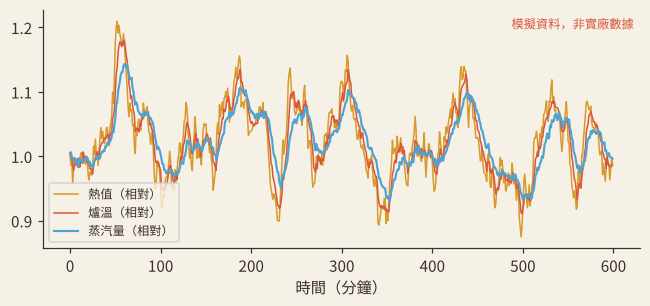

熱值和蒸汽量的相關係數：0.77（模擬）


In [3]:
q_fixed = lhv / MU                                   # heat input, relative
temp_fixed = lag(q_fixed, 4) + rng.normal(0, 0.004, N)
steam_fixed = lag(q_fixed, 10) + rng.normal(0, 0.003, N)

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(t, q_fixed, color=AMBER, lw=1, label="熱值（相對）")
ax.plot(t, temp_fixed, color=RED, lw=1, label="爐溫（相對）")
ax.plot(t, steam_fixed, color=BLUE, lw=1.4, label="蒸汽量（相對）")
ax.set_xlabel("時間（分鐘）"); ax.legend(fontsize=8, loc="lower left"); tag(ax); plt.show()
r = np.corrcoef(lhv, steam_fixed)[0, 1]
print(f"熱值和蒸汽量的相關係數：{r:.2f}（模擬）")

## 3. 熱負荷上限（簡化示意）
爐子每小時能承受的熱量有上限。用最簡單的假設：設計熱值 1500 大卡/公斤時剛好燒滿設計量；熱值更高時，熱量先碰到上限，每小時能燒的垃圾 = 上限 ÷ 熱值。
真實焚化爐還有機械負荷等限制（燃燒圖 firing diagram），這裡**只是示意**，不代表任何一座廠的處理量。

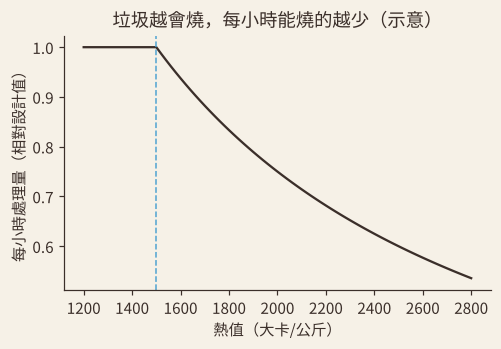

In [4]:
DESIGN_LHV = 1500.0
lhv_axis = np.linspace(1200, 2800, 81)
throughput = np.minimum(1.0, DESIGN_LHV / lhv_axis)      # relative to design tonnage
assert throughput[0] == 1.0 and np.all(np.diff(throughput) <= 0)

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(lhv_axis, throughput, color=INK)
ax.axvline(DESIGN_LHV, ls="--", color=BLUE, lw=1)
ax.set_xlabel("熱值（大卡/公斤）"); ax.set_ylabel("每小時處理量（相對設計值）")
ax.set_title("垃圾越會燒，每小時能燒的越少（示意）")
plt.show()

## 4. 焚化廠的資料：一條條時間序列
現在加上一個簡單的自動控制：蒸汽量偏高就少送一點垃圾，偏低就多送一點（積分控制，增益 0.2）。
其他感測器也跟著動：含氧量和爐內放熱反向、一次空氣量跟著進料、爐內壓力隨放熱變化抖動；爐溫偏低或氧氣過多時，一氧化碳會冒出尖峰。全部都是**相對值**。

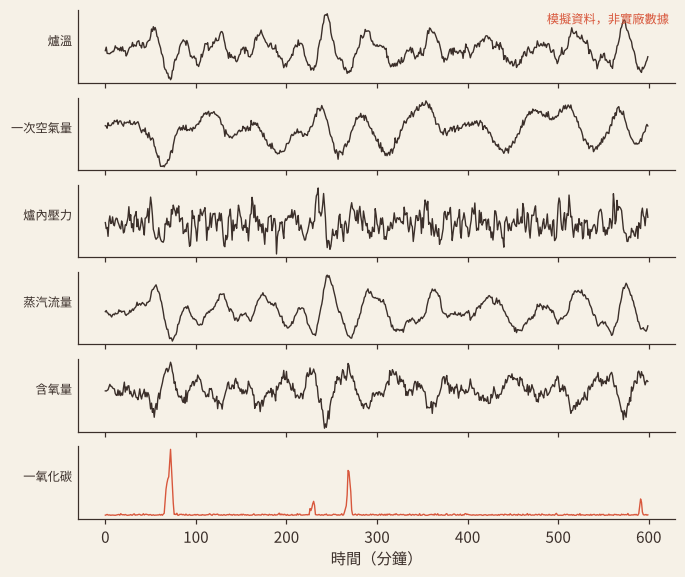

自動控制讓蒸汽量的標準差從 0.043 降到 0.031（相對值，模擬）
一氧化碳尖峰次數：5


In [5]:
F = np.ones(N); Q = np.ones(N); steam = np.ones(N); temp = np.ones(N); o2_lag = np.ones(N)
for i in range(N):
    Q[i] = F[i] * lhv[i] / MU
    if i > 0:
        steam[i] = steam[i - 1] + (Q[i] - steam[i - 1]) / 10
        temp[i] = temp[i - 1] + (Q[i] - temp[i - 1]) / 4
        o2_lag[i] = o2_lag[i - 1] + (Q[i] - o2_lag[i - 1]) / 3
    if i + 1 < N:
        F[i + 1] = np.clip(F[i] - 0.2 * (steam[i] - 1.0), 0.8, 1.2)

steam_m = steam + rng.normal(0, 0.003, N)
temp_m = temp + rng.normal(0, 0.008, N)
o2 = 1 - 0.8 * (o2_lag - 1) + rng.normal(0, 0.012, N)
air = 1 + 0.5 * (F - 1) + rng.normal(0, 0.004, N)
press = lag(np.r_[0, np.diff(Q)] * 5, 2) + rng.normal(0, 0.01, N)
co = 0.03 + 10 * np.clip(0.93 - temp, 0, None) + 5 * np.clip(o2 - 1.08, 0, None) + np.abs(rng.normal(0, 0.006, N))

sensors = {"爐溫": temp_m, "一次空氣量": air, "爐內壓力": press, "蒸汽流量": steam_m, "含氧量": o2, "一氧化碳": co}
fig, axs = plt.subplots(len(sensors), 1, figsize=(7, 6), sharex=True)
for ax, (name, s) in zip(axs, sensors.items()):
    ax.plot(t, s, lw=0.9, color=RED if name == "一氧化碳" else INK); ax.set_ylabel(name, rotation=0, ha="right", fontsize=8)
    ax.set_yticks([])
axs[-1].set_xlabel("時間（分鐘）"); tag(axs[0]); plt.show()
events = int((np.diff((co > 0.08).astype(int)) == 1).sum())
print(f"自動控制讓蒸汽量的標準差從 {steam_fixed.std():.3f} 降到 {steam.std():.3f}（相對值，模擬）")
print(f"一氧化碳尖峰次數：{events}")

## 5. 三種資料：即時、慢半拍、很少量到
- **即時**：爐溫每分鐘都有。
- **慢半拍**：煙囪量到的一氧化碳，是爐內的一氧化碳經過一段路、再被儀器平均之後的樣子。這裡**假設**延遲 D = 6 個時間步，只為示意，不代表真實的秒數。用交叉相關找回這個延遲。
- **很少量到**：熱值很難直接量，這裡假設每 150 分鐘才有一個取樣值。（戴奧辛依法一年定期檢測兩次，時間尺度更長，影片用示意圖表現。）

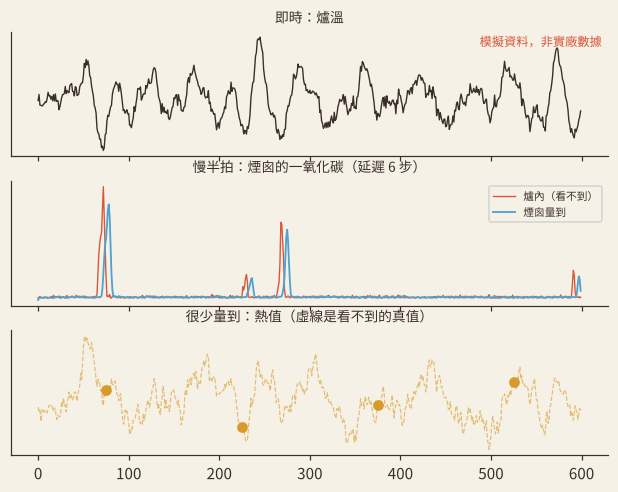

交叉相關最大的位移 = 6 步（和假設的 D 相同）


In [6]:
D = 6
stack_co = np.convolve(np.r_[np.full(D, co[0]), co[:-D]], np.ones(3) / 3, mode="same")
lags = np.arange(0, 16)
xcorr = np.array([np.corrcoef(co[:N - k], stack_co[k:])[0, 1] for k in lags])
best = int(lags[np.argmax(xcorr)])
assert best == D, best

sample_idx = np.arange(75, N, 150)
fig, axs = plt.subplots(3, 1, figsize=(7, 5), sharex=True)
axs[0].plot(t, temp_m, color=INK, lw=0.9); axs[0].set_title("即時：爐溫", fontsize=9)
axs[1].plot(t, co, color=RED, lw=0.9, label="爐內（看不到）"); axs[1].plot(t, stack_co, color=BLUE, lw=1.2, label="煙囪量到")
axs[1].legend(fontsize=7); axs[1].set_title(f"慢半拍：煙囪的一氧化碳（延遲 {best} 步）", fontsize=9)
axs[2].plot(t, lhv, color=AMBER, lw=0.8, ls="--", alpha=0.6); axs[2].plot(sample_idx, lhv[sample_idx], "o", color=AMBER)
axs[2].set_title("很少量到：熱值（虛線是看不到的真值）", fontsize=9)
for ax in axs: ax.set_yticks([])
tag(axs[0]); plt.show()
print(f"交叉相關最大的位移 = {best} 步（和假設的 D 相同）")

## 6. 軟感測器：用量得到的，推估熱值
用前 70% 的時間訓練一個**線性迴歸**，輸入是即時量得到的：爐溫、爐溫變化、進料、含氧量、蒸汽量；輸出是熱值。再拿後 30% 測試。
這就是下一集（EP03 多變數線性迴歸）要細講的方法。

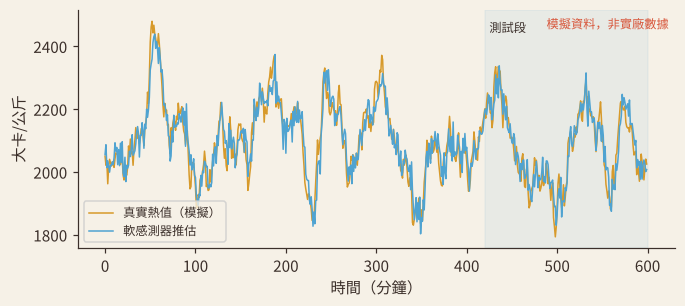

測試段：平均絕對誤差 33 大卡/公斤，R² = 0.89（模擬資料，真實工廠通常更難）


In [7]:
dtemp = np.r_[0, np.diff(temp_m)]
X = np.c_[np.ones(N), temp_m, dtemp, F, o2, steam_m]
n_train = int(N * 0.7)
coef, *_ = np.linalg.lstsq(X[:n_train], lhv[:n_train], rcond=None)
lhv_hat = X @ coef
test = slice(n_train, N)
mae = float(np.abs(lhv_hat[test] - lhv[test]).mean())
r2 = float(1 - ((lhv_hat[test] - lhv[test]) ** 2).sum() / ((lhv[test] - lhv[test].mean()) ** 2).sum())
assert r2 > 0.8, r2

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(t, lhv, color=AMBER, lw=1, label="真實熱值（模擬）")
ax.plot(t, lhv_hat, color=BLUE, lw=1, label="軟感測器推估")
ax.axvspan(n_train, N, color=BLUE, alpha=0.08); ax.text(n_train + 5, lhv.max(), "測試段", fontsize=8, va="top")
ax.set_xlabel("時間（分鐘）"); ax.set_ylabel("大卡/公斤"); ax.legend(fontsize=8, loc="lower left"); tag(ax); plt.show()
print(f"測試段：平均絕對誤差 {mae:.0f} 大卡/公斤，R² = {r2:.2f}（模擬資料，真實工廠通常更難）")

## 7. 提早示警
模擬一個慢慢變糟的狀況：第 150 分鐘後，爐溫（相對值）開始緩慢下降。
- **硬警報**：數值跌破 0.93 才響。
- **提早示警**：最近 15 分鐘的平均，比正常時期的平均低了 3 個標準差就提醒。

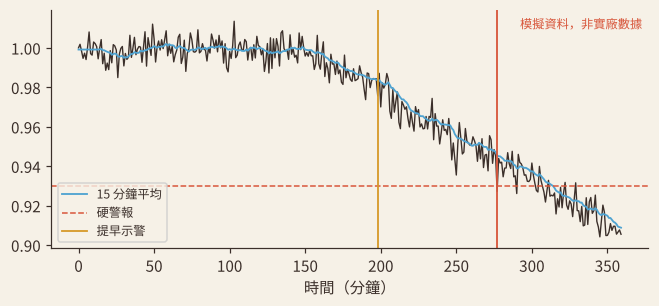

提早示警在第 198 分鐘，硬警報在第 277 分鐘，早了 79 分鐘（模擬）


In [8]:
rng2 = np.random.default_rng(7)
M = 360
y_warn = 1.0 + rng2.normal(0, 0.006, M) + np.where(np.arange(M) > 150, -(np.arange(M) - 150) * 0.00045, 0)
THRESHOLD = 0.93
mu0, sd0 = y_warn[:120].mean(), y_warn[:120].std()
roll = np.convolve(y_warn, np.ones(15) / 15, mode="full")[:M]; roll[:14] = mu0
t_alarm = int(np.argmax(y_warn < THRESHOLD))
t_early = int(np.argmax(roll < mu0 - 3 * sd0))
assert t_early < t_alarm

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(y_warn, color=INK, lw=0.9); ax.plot(roll, color=BLUE, lw=1.2, label="15 分鐘平均")
ax.axhline(THRESHOLD, color=RED, ls="--", lw=1, label="硬警報")
ax.axvline(t_early, color=AMBER, lw=1.2, label="提早示警"); ax.axvline(t_alarm, color=RED, lw=1.2)
ax.set_xlabel("時間（分鐘）"); ax.legend(fontsize=8, loc="lower left"); tag(ax); plt.show()
print(f"提早示警在第 {t_early} 分鐘，硬警報在第 {t_alarm} 分鐘，早了 {t_alarm - t_early} 分鐘（模擬）")

## 8. 匯出資料給影片使用
影片（Remotion）讀這個 JSON 來畫圖，所以影片裡的圖和這本 notebook 完全一樣。長的序列每 2 分鐘取一點。

In [9]:
r4 = lambda v: [round(float(x), 4) for x in v]
ds = slice(0, N, 2)
norm = lambda s: (s - s.min()) / (s.max() - s.min())
out = {
    "meta": {"seed": 2026, "minutes": N, "step_export": 2, "simulated": True, "label": LABEL},
    "reported": {"design_lhv": 1500, "actual_lhv": 2300, "unit": "大卡/公斤", "simulated": False,
                 "source": "公視新聞網 2021/1/6"},
    "lhv": {"t": r4(t[ds]), "v": r4(lhv[ds]), "mean": float(lhv.mean())},
    "fixed_feed": {"q": r4(q_fixed[ds]), "temp": r4(temp_fixed[ds]), "steam": r4(steam_fixed[ds]), "corr": float(r)},
    "throughput": {"lhv": r4(lhv_axis), "rel": r4(throughput), "design_lhv": DESIGN_LHV, "label": "示意圖"},
    "sensors": {name: r4(norm(s)[ds]) for name, s in sensors.items()},
    "delay": {"furnace_co": r4(norm(co)[ds]), "stack_co": r4(norm(stack_co)[ds]), "D": D},
    "sparse": {"idx": [int(i) for i in sample_idx], "lhv": r4(lhv[sample_idx])},
    "soft": {"n_train": n_train, "true": r4(lhv[ds]), "est": r4(lhv_hat[ds]), "mae": mae, "r2": r2},
    "warn": {"y": r4(y_warn[::2]), "roll": r4(roll[::2]), "threshold": THRESHOLD, "t_early": t_early, "t_alarm": t_alarm},
}
Path("data").mkdir(exist_ok=True)
Path("data/v03.json").write_text(json.dumps(out, ensure_ascii=False), encoding="utf-8")
print("已匯出 data/v03.json")

已匯出 data/v03.json
